# It's a Metric, Too

Initially, I came up with two possible approaches to solve this puzzle - either via CSP solver or by hand. I decided to go with the by hand approach since I thought it will be more fun


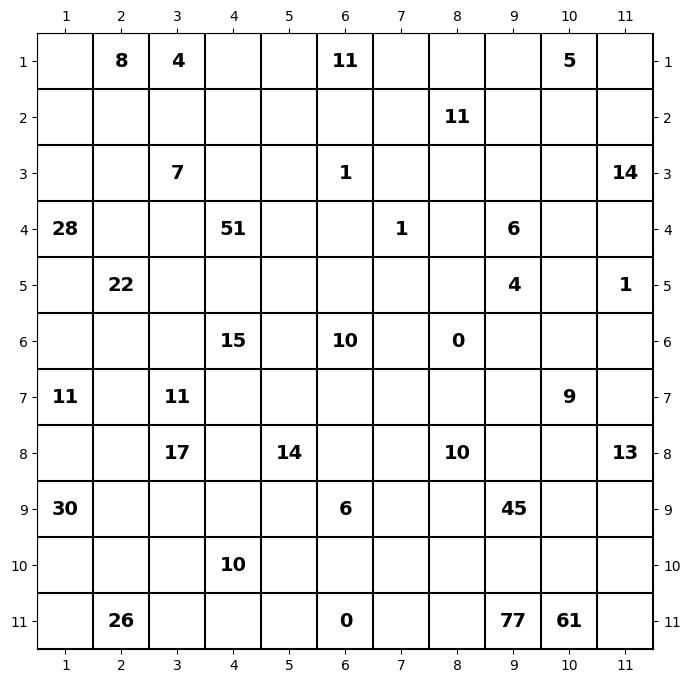

In [30]:
from utils import *

sol = Solution()
sol.visualize()

## Observations

I will index rows and columns from 1 and denote row 2, column 5 as $(2,5)$. When I mention a number, I mean a distance number from the puzzle input.

* There are 2 forced states of size 1: one at $(3,7)$ and the second at $(6,11)$.
* 51 is too close to 7, so it must belong to a large state.
* 77 is too close to a state capital, so it also implies a large state. Probably the same one as 51?
* $61 = 5 \cdot 12 + 1$, so there might be a path over a state of size 12 to the capital at $(6,11)$. This also fits the number 13 on the way.
* 45 is three steps from 9; the difference is $36 = 12 \cdot 3$, so there might really be a state of size 12.
* The two 11s at $(7,1)$ and $(7,3)$ might go to a state of size 11 with its capital at $(7,2)$. This also fits the number 22 above.
* 30 at $(9,1)$ might go to the same capital via 3 steps over a state of size 10.
* The capital at $(11,6)$ belongs to either a small state (size 1, 3, or 5) or the largest one (containing 77).

## Next steps

I focused a lot on the capital at $(11,6)$. I managed to prove that its size cannot be 1 or 5, so I went with a size of 3.
After that conclusion, 77 must lie in a state of size 37, as $77 = 37 \cdot 2 + 3$.

Combining all this information, I came up with a structure that fulfilled all these observations and looked like a good partial solution.

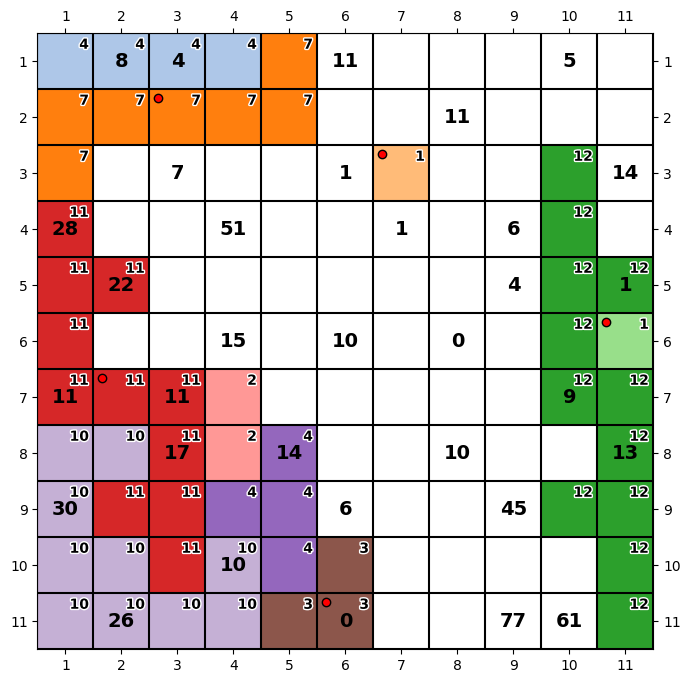

In [31]:
states = [
    {
        "id": 1,
        "capital": None,
        "cells": [(1, 1), (1, 2), (1, 3), (1, 4)]
    },
    {
        "id": 2,
        "capital": (2, 3),
        "cells": [(1, 5), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (3, 1)]
    },
    {
        "id": 3,
        "capital": (3, 7),
        "cells": [(3, 7)]
    },
    {
        "id": 4,
        "capital": None,
        "cells": [(3, 10), (4, 10), (5, 10), (5, 11), (6, 10), (7, 10), (7, 11), (8, 11), (9, 10), (9, 11), (10, 11), (11, 11)]
    },
    {
        "id": 5,
        "capital": (6, 11),
        "cells": [(6, 11)]
    },
    {
        "id": 6,
        "capital": (7, 2),
        "cells": [(4, 1), (5, 1), (5, 2), (6, 1), (7, 1), (7, 2), (7, 3), (8, 3), (9, 2), (9, 3), (10, 3)]
    },
    {
        "id": 7,
        "capital": None,
        "cells": [(7, 4), (8, 4)]
    },
    {
        "id": 8,
        "capital": None,
        "cells": [(8, 5), (9, 4), (9, 5), (10, 5)]
    },
    {
        "id": 9,
        "capital": None,
        "cells": [(8, 1), (8, 2), (9, 1), (10, 1), (10, 2), (10, 4), (11, 1), (11, 2), (11, 3), (11, 4)]
    },
    {
        "id": 10,
        "capital": (11, 6),
        "cells": [(10, 6), (11, 5), (11, 6)]
    }
]

fill_states(sol, states)

sol.visualize()

After that, I tried to fill in the biggest state of size 37. Lucky enough, It was easy to see the symmetry

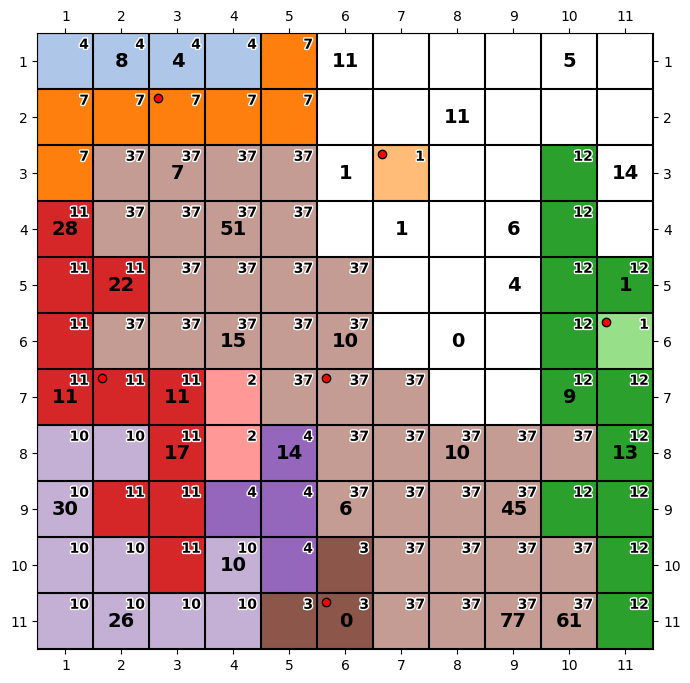

In [32]:
states = [
    {
        "id": 11,
        "capital": (7, 6),
        "cells": [(3, 2), (3, 3), (3, 4), (3, 5), (4, 2), (4, 3), (4, 4), (4, 5), (5, 3), (5, 4), (5, 5), (5, 6), 
                  (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (7, 5), (7, 6), (7, 7), (8, 6), (8, 7), (8, 8), (8, 9), 
                  (8, 10), (9, 6), (9, 7), (9, 8), (9, 9), (10, 7), (10, 8), (10, 9), (10, 10), (11, 7), (11, 8), (11, 9), (11, 10)]
    }
]

fill_states(sol, states)

sol.visualize()

Next obvious state of size 5 is the one with center at $(6,8)$ and another of size two right next to it, so that the 6 and 4 can travel there with these costs

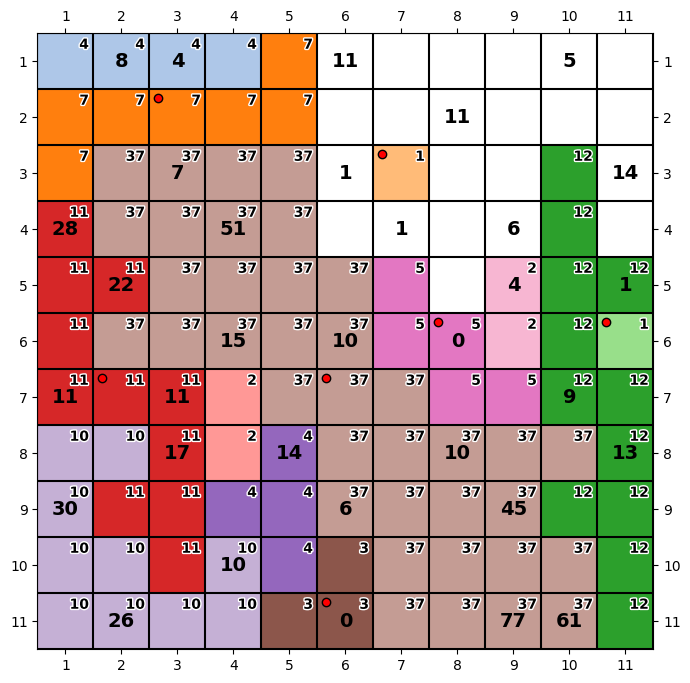

In [33]:
states = [
    {
        "id": 12,
        "capital": (6, 8),
        "cells": [(5, 7), (6, 7), (6, 8), (7, 8), (7, 9)]
    },
    {
        "id": 13,
        "capital": None,
        "cells": [(5, 9), (6, 9)]
    },
]

fill_states(sol, states)

sol.visualize()

And the rest was easy to fill

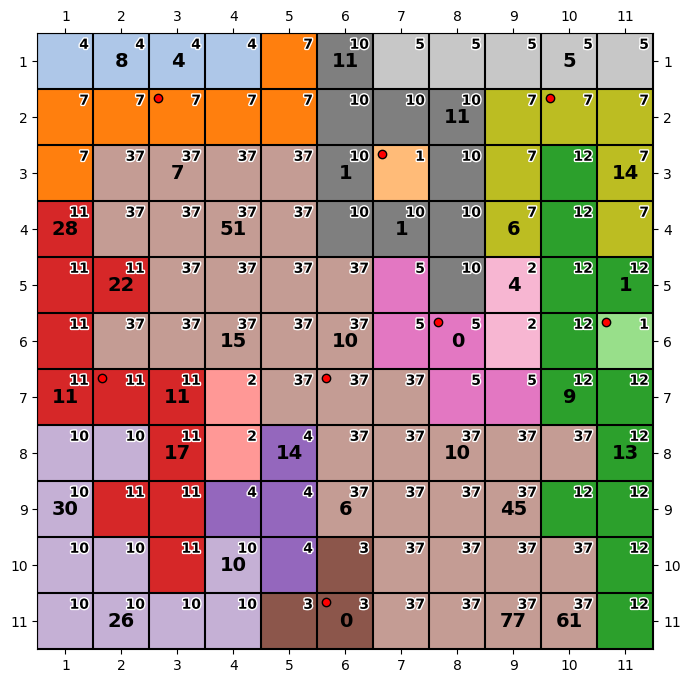

In [34]:
states = [
    {
        "id": 14,
        "capital": None,
        "cells": [(1, 6), (2, 6), (2, 7), (2, 8), (3, 6), (3, 8), (4, 6), (4, 7), (4, 8), (5, 8)]
    },
    {
        "id": 15,
        "capital": (2, 10),
        "cells": [(1, 7), (1, 8), (1, 9), (1, 10), (1, 11)]
    },
    {
        "id": 16,
        "capital": (2, 10),
        "cells": [(2, 9), (2, 10), (2, 11), (3, 9), (3, 11), (4, 9), (4, 11)]
    }
]

fill_states(sol, states)

sol.visualize()

## Solution

In [35]:
print(f"The final asnwer is {sol.get_final_answer()}")

The final asnwer is 408951
